# 🏢 Anticipez les besoins en consommations de bâtiments (Modélisation)

## 📋 Présentation du Projet
Dans le cadre de son engagement pour la **neutralité carbone d'ici 2050**, la ville de Seattle analyse les données de consommation énergétique de ses bâtiments non résidentiels.

* **Objectif :** Prédire les émissions de CO2 et la consommation totale d'énergie.
* **Cible :** Bâtiments non destinés à l'habitation.

##  1. Imports des modules et du dataset


### Stack Logicielle
| Modules |
| :--- |
| `matplotlib` |
| `pandas` |
| `seaborn` |
| `sickit-learn` |
| `numpy` |
| `category_encoders` |
| `scipy` |

### Source des données
* **Fichier** : `..data/processed/dataset_clean_ghge.csv`
*  **Format** : CSV

---

##  2. Fonction pour validation de modèle

###  Entrées
Notre fonction va prendre en entrées :
* **Le modèle choisi**
* **Notre dataset sans la variable cible**
* **La variable cible**

### Métriques d'évaluation
* **R2** : pourcentage de réduction de l'erreur par rapport à une estimation basée sur la moyenne
* **MAE** : erreur moyenne absolue
* **RMSE** : Racine carré de l'erreur quadratique
* **Time** : la durée d'entrainement de notre modèle

### Sorties
Retourne le tableau des métriques d'évaluation pour le train et le test

## 3. Test de différents modèles

### Régression linéaire

| Métrique | R² | MAE | RMSE | Time (sec) |
| :--- | :---: | :---: | :---: | :---: |
| **Train (Fit)** | 0.601039 | 0.262980 | 0.352149 | 0.041313 |
| **Test (Score)** | 0.474662 | 0.296656 | 0.402189 | 0.007953 |

Le modèle obtient des résultats satisfaisants

### RandomForestRegressor

| Métrique | R² | MAE | RMSE | Time (sec) |
| :--- | :---: | :---: | :---: | :---: |
| **Train (Fit)** | 0.931489 | 0.102152 | 0.145910 | 1.847071 |
| **Test (Score)** | 0.516459 | 0.271864 | 0.385904 | 0.030972 |

On observe de l'overfitting

### SVR
| Métrique | R² | MAE | RMSE | Time (sec) |
| :--- | :---: | :---: | :---: | :---: |
| **Train (Fit)** | 0.721284 | 0.198500 | 0.294373 | 0.131417 |
| **Test (Score)** | 0.460254 | 0.288166 | 0.407916 | 0.049843 |

Les mauvais résultats de ces modèles pourraient être améliorés en retravaillant les données. L'ordre de grandeur entre les 2 variables étant différents, la variable d'énergie a plus bénéficié du nettoyage actuel des données.

## 4. Optimisation

On utilise la methode GridSearchCV pour tester différentes combinaisons d'hyperparamètres sur un modèle à améliorer.
Post traitement, on arrive à réduire l'overfitting du RandomForestRegressor.

| Métrique | R² | MAE | RMSE | Time (sec) |
| :--- | :---: | :---: | :---: | :---: |
| **Train (Fit)** | 0.748343 | 0.196076 | 0.279675 | 0.658002 |
| **Test (Score)** | 0.510771 | 0.278598 | 0.388059 | 0.063001 |

On peut ensuite utiliser l'attribut **feature_importance** pour mettre en évidence les features ayant le plus d'impact dans la prédiction :
- HasGas                                             
- HasSteam                                           
- LogPropertyGFABuilding(s)
- LogLargestPropertyUseTypeGFA
- Supermarket / Grocery Store 

# Modélisation 

### Import des modules 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
import numpy as np
pd.set_option("display.max_columns", 200)
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
    KFold
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

from sklearn.pipeline import Pipeline

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier



Import du dataset

In [2]:
df = pd.read_csv("../data/processed/dataset_clean_ghge.csv")
df = df.drop(columns=["ENERGYSTARScore"])

Détails de la fonction permettant de tester et d'évaluer les modèles :
1. On entre les caractéristiques de notre validation croisée :
    - On divise le jeu en 5 fold
    - On fixe un random_state pour pouvoir obtenir le même aléatoire pour nos différents tests
2. On définit nos métriques d'évaluation :
    * **R2** : pourcentage de réduction de l'erreur par rapport à une estimation basée sur la moyenne
    * **MAE** : erreur moyenne absolue
    * **RMSE** : Racine carré de l'erreur quadratique
    * **Time** : la durée d'entrainement de notre modèle
3. On entraine et teste le modèle selon les paramètres définies précédemment
4. On affiche les métriques d'évaluations du modèle

In [3]:
def modele_validation(modele, X, y):

    cv_details = KFold(n_splits=5, shuffle=True, random_state=42)
    
    scoring = ['r2', 'neg_mean_absolute_error', 'neg_root_mean_squared_error']

    cross_validation_result = cross_validate(modele, X, y, cv=cv_details, scoring=scoring, return_train_score=True)
    
    dict_resultats = {
        "R2": [np.mean(cross_validation_result["train_r2"]), np.mean(cross_validation_result["test_r2"])],
        "MAE": [-np.mean(cross_validation_result["train_neg_mean_absolute_error"]), -np.mean(cross_validation_result["test_neg_mean_absolute_error"])],
        "RMSE": [-np.mean(cross_validation_result["train_neg_root_mean_squared_error"]), -np.mean(cross_validation_result["test_neg_root_mean_squared_error"])],
        "Time (sec)": [np.mean(cross_validation_result["fit_time"]), np.mean(cross_validation_result["score_time"])]
    }
    
    df_visuel = pd.DataFrame(dict_resultats, index=["Train (Fit)", "Test (Score)"])
    display(df_visuel)

In [4]:
# On définit notre variable cible
y = df["LogGHGEmissionsIntensity"]

# On créé 2 df sans variable cible et avec et sans EnergySTARSCORE
X = df.drop(columns=["LogGHGEmissionsIntensity"])

# Pour interpréter MAE et RMSE, on récupère la moyenne de notre valeur cible
moyenne = df["LogGHGEmissionsIntensity"].mean()
print(moyenne)


0.7554696699804575


## Test de différents modèles

#### LINEAR REGRESSION

In [5]:
model = LinearRegression()

print("Résultat régression linéaire")
modele_validation(model, X, y)


Résultat régression linéaire


,R2,MAE,RMSE,Time (sec)
Train (Fit),0.556390,0.277607,0.371308,0.048615
Test (Score),0.429855,0.310226,0.418768,0.024178


Interprétation des résultats :
- Résultats trop faibles du R2
- MAE et RMSE énormes pour l'ordre de grandeur
- Time correct

In [6]:
model = RandomForestRegressor()

print("Résultat RandomForestRegressor")
modele_validation(model, X, y)

Résultat RandomForestRegressor


,R2,MAE,RMSE,Time (sec)
Train (Fit),0.927964,0.105395,0.149618,1.694790
Test (Score),0.484776,0.281899,0.398151,0.028335


Interprétation des résultats : 
- Ici notre modèle fait clairement de l'overfitting
- MAE et RMSE conséquent par rapport à l'ordre de grandeur
- Time correct

In [7]:
model = SVR()

print("Résultat SVR")
modele_validation(model, X, y)

# Normalisation des données
pipeline_svr = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

print("Résultat SVR avec normalisation")
modele_validation(pipeline_svr, X, y)

Résultat SVR


,R2,MAE,RMSE,Time (sec)
Train (Fit),-0.017584,0.421772,0.562450,0.187338
Test (Score),-0.030605,0.425516,0.564108,0.063443


Résultat SVR avec normalisation


,R2,MAE,RMSE,Time (sec)
Train (Fit),0.680708,0.214003,0.315052,0.155477
Test (Score),0.420053,0.300822,0.422309,0.053369


Interprétation des résultats : 
- Ici notre modèle fait clairement de l'overfitting
- MAE et RMSE conséquent par rapport à l'ordre de grandeur
- Time correct

Les mauvais résultats de ces modèles pourraient être améliorés en retravaillant les données. L'ordre de grandeur entre les 2 variables étant différents, la variable d'énergie a plus bénéficié du nettoyage actuel des données.

### Optimisation d'un modèle

In [8]:
cv_details = KFold(n_splits=5, shuffle=True, random_state=42)

parameters = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_leaf': [4, 10, 20, 30, 40],
    'max_features': [0.2, 0.4, 0.6, 'sqrt']
}
model = RandomForestRegressor()

rfg = GridSearchCV(model, parameters, cv = cv_details, scoring = 'r2', verbose = 1)
rfg.fit(X,y)
display(rfg.best_params_)
display(rfg.best_score_)

Fitting 5 folds for each of 200 candidates, totalling 1000 fits


{'max_depth': 15,
 'max_features': 0.4,
 'min_samples_leaf': 4,
 'n_estimators': 100}

np.float64(0.49174619623492477)

In [9]:
model = RandomForestRegressor(
    max_depth=20,
    max_features=0.4,
    min_samples_leaf=4,
)

print("Résultat RandomForestRegressor")
modele_validation(model, X, y)

Résultat RandomForestRegressor


,R2,MAE,RMSE,Time (sec)
Train (Fit),0.721134,0.209176,0.294374,0.637100
Test (Score),0.489809,0.285533,0.396219,0.026876


On récupère le meilleur modèle suite à la gridsearchcv pour identifier les features ayant le plus d'impact

In [10]:
best_model = rfg.best_estimator_
importances = best_model.feature_importances_
feature_imp = pd.Series(
    importances, index=X.columns
).sort_values(ascending=False)
display(feature_imp)

HasGas                                 0.268147
HasSteam                               0.068795
LogPropertyGFABuilding(s)              0.052405
LogLargestPropertyUseTypeGFA           0.050361
Supermarket / Grocery Store            0.048300
                                         ...   
Prison/Incarceration                   0.000000
Strip Mall                             0.000000
Social/Meeting Hall                    0.000000
Urgent Care/Clinic/Other Outpatient    0.000000
Wholesale Club/Supercenter             0.000000
Length: 94, dtype: float64

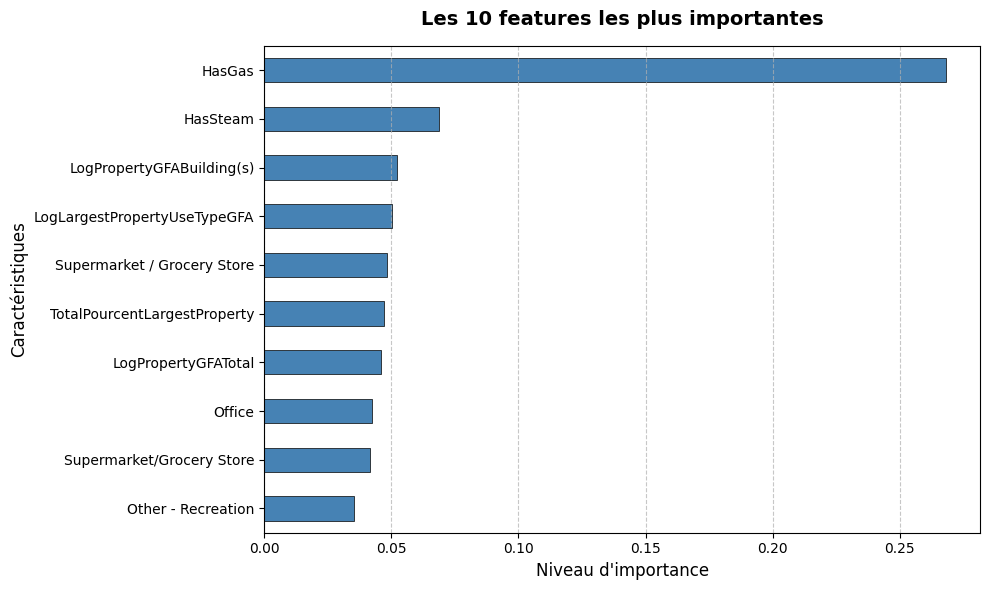

In [11]:
top_10 = feature_imp.head(10)

plt.figure(figsize=(10, 6))

top_10.sort_values(ascending=True).plot(
    kind='barh', 
    color='steelblue', 
    edgecolor='black', 
    linewidth=0.5
)

plt.title("Les 10 features les plus importantes", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Niveau d'importance", fontsize=12)
plt.ylabel("Caractéristiques", fontsize=12)

plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()

plt.show()